# Laboratório - Classificação com Naive Bayes

## Ajustando Ambiente

In [148]:
%%capture
!pip install nltk matplotlib-venn

In [149]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib_venn import venn2

import nltk
from nltk.corpus import stopwords

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, strip_accents_unicode
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

## Objetivos de aprendizagem

Ao final deste laboratório, espera-se que o estudante seja capaz de:

* Explicar como o Teorema de Bayes é usado em classificação e o que significa a hipótese de independência condicional.
* Preparar mensagens de texto e separar os dados em treino e teste.
* Calcular probabilidades a priori e verossimilhanças a partir de frequências.
* Identificar o problema da probabilidade zero e resolvê-lo com a suavização de Laplace.
* Classificar uma nova mensagem pela regra de decisão MAP, à mão e com o `scikit-learn`.
* Avaliar um classificador em dados não vistos, interpretando matriz de confusão, precisão, revocação e F1.

## Motivação

O Teorema de Bayes fornece uma forma de atualizar nossas crenças diante de novas evidências. Em Inteligência Artificial, essa ideia é particularmente útil quando queremos tomar decisões sob incerteza.

Neste laboratório, vamos usar essa ideia para construir um classificador de mensagens. A pergunta central será: dada uma nova mensagem, ela parece mais compatível com a classe Normal ou com a classe Spam?

O classificador Naive Bayes responde a essa pergunta combinando duas informações: a frequência com que cada classe aparece no treinamento e a frequência com que cada palavra aparece em cada classe. Apesar de simples, esse modelo é uma porta de entrada importante para compreender classificação probabilística, representação textual e tomada de decisão baseada em evidências.

## Fundamentação Teórica

### Naive Bayes

O Teorema de Bayes nos mostrou como calcular a probabilidade de uma causa dado um único efeito. Em uma tarefa de classificação, temos uma causa, a classe $C$, e vários efeitos, como as palavras $E_1, E_2, \dots, E_n$ de um e-mail. Queremos, portanto, calcular:

$$P(C | E_1, \dots, E_n) = \frac{P(E_1, \dots, E_n | C) \cdot P(C)}{P(E_1, \dots, E_n)}$$

O termo $P(E_1, \dots, E_n | C)$ é a probabilidade conjunta das evidências. Em geral, as evidências dependem umas das outras: saber que um e-mail contém "promoção" muda o que esperamos encontrar no restante dele. Calcular esse termo exigiria dados sobre todas as combinações possíveis de palavras, o que é inviável na prática.

O classificador Naive Bayes contorna o problema com uma suposição simplificadora, a **independência condicional**: uma vez conhecida a classe, a ocorrência de uma palavra não altera a probabilidade de outra. É uma suposição "ingênua" (*naive*), mas transforma a probabilidade conjunta em um simples produto:

$$P(E_1, \dots, E_n | C) = \prod_{i=1}^{n} P(E_i | C)$$

Substituindo esse produto na Regra de Bayes, chegamos à fórmula do Naive Bayes:

$$P(C | E_1, \dots, E_n) = \frac{P(C) \cdot \prod_{i=1}^{n} P(E_i | C)}{P(E_1, \dots, E_n)}$$

No numerador estão a probabilidade a priori da classe, $P(C)$, e o produto das **verossimilhanças** de cada palavra. O denominador, chamado de evidência, apenas normaliza o resultado para que as probabilidades somem 1.

#### Demonstração

Vamos acompanhar a fórmula em um exemplo pequeno, com valores hipotéticos. Imagine uma mensagem que contém apenas as palavras "oferta" e "gratis", ambas muito mais comuns em Spam do que em mensagens Normais. Começamos declarando o que o modelo já saberia:

In [150]:
# Probabilidades a priori das classes
p_normal = 0.5
p_spam = 0.5

# Nova mensagem já pré-processada e tokenizada
message_tokens = ["oferta", "gratis"]
print("Tokens da mensagem:", message_tokens)

# Verossimilhanças hipotéticas: P(palavra | classe)
demo_likelihood_normal = {"oferta": 0.01, "gratis": 0.01}
demo_likelihood_spam = {"oferta": 0.10, "gratis": 0.08}

Tokens da mensagem: ['oferta', 'gratis']


Agora calculamos o numerador da fórmula, que chamaremos de *score*, para cada uma das classes:

In [151]:
# Numerador de Bayes para a classe Normal: priori × produto das verossimilhanças
score_normal_demo = p_normal * np.prod([demo_likelihood_normal[word] for word in message_tokens])

print("Score de Normal (priori × verossimilhanças):")
print(f"P(Normal) × P(oferta | Normal) × P(gratis | Normal) = {score_normal_demo:.6f}")

Score de Normal (priori × verossimilhanças):
P(Normal) × P(oferta | Normal) × P(gratis | Normal) = 0.000050


In [152]:
# Numerador de Bayes para a classe Spam: priori × produto das verossimilhanças
score_spam_demo = p_spam * np.prod([demo_likelihood_spam[word] for word in message_tokens])

print("Score de Spam (priori × verossimilhanças):")
print(f"P(Spam) × P(oferta | Spam) × P(gratis | Spam)   = {score_spam_demo:.6f}")

Score de Spam (priori × verossimilhanças):
P(Spam) × P(oferta | Spam) × P(gratis | Spam)   = 0.004000


Somando os scores de todas as classes, obtemos a evidência. Ao dividir cada score por ela, os valores se tornam probabilidades que somam 1:

In [153]:
# Evidência: soma dos scores de todas as classes
evidence = score_normal_demo + score_spam_demo

print("Evidência:")
print(f"P(Normal) × P(oferta | Normal) × P(gratis | Normal) + P(Spam) × P(oferta | Spam) × P(gratis | Spam) = {evidence:.6f}")

Evidência:
P(Normal) × P(oferta | Normal) × P(gratis | Normal) + P(Spam) × P(oferta | Spam) × P(gratis | Spam) = 0.004050


In [154]:
# Probabilidade a posteriori de cada classe
posterior_normal_demo = score_normal_demo / evidence
posterior_spam_demo = score_spam_demo / evidence

print("Probabilidade Posterior:")
print(f"P(Normal | oferta, gratis) = {posterior_normal_demo:.6f}")
print(f"P(Spam | oferta, gratis) = {posterior_spam_demo:.6f}")

Probabilidade Posterior:
P(Normal | oferta, gratis) = 0.012346
P(Spam | oferta, gratis) = 0.987654


### Como funciona o Classificador (Regra de Decisão MAP)

O classificador escolhe a classe mais provável diante das evidências, princípio conhecido como **Máxima Probabilidade A Posteriori** (MAP). Como o denominador é o mesmo para todas as classes, ele não altera qual delas fica em primeiro lugar. Basta, então, comparar os numeradores:

$$\text{Decisão}_{MAP} = \arg \max_{C_k} \left[ P(C_k) \cdot \prod_{i=1}^{n} P(E_i | C_k) \right]$$

Em outras palavras, o agente calcula o score de cada classe e escolhe o maior, sem precisar da evidência. No nosso exemplo:

In [155]:
predicted_class = "Spam" if score_spam_demo > score_normal_demo else "Normal"
print(f"Classe prevista: {predicted_class}")

Classe prevista: Spam


### Por que somar logaritmos

Nosso exemplo tinha só duas palavras, mas uma mensagem real pode ter centenas. Multiplicar muitas probabilidades pequenas produz um número tão próximo de zero que o computador não consegue representá-lo, problema conhecido como *underflow*. Veja o que acontece com 200 palavras de probabilidade 0,01:

In [156]:
print(f"Produto das probabilidades: {0.01 ** 200}")
print(f"Soma dos logaritmos:        {200 * np.log(0.01):.2f}")

Produto das probabilidades: 0.0
Soma dos logaritmos:        -921.03


O produto desaparece, enquanto a soma dos logaritmos continua sendo um número comum. A troca não muda a decisão, porque o logaritmo preserva a ordem entre os valores: se um score é maior que o outro, seu logaritmo também é. Vamos confirmar com o exemplo anterior:

In [157]:
log_score_normal = np.log(p_normal) + np.log([demo_likelihood_normal[word] for word in message_tokens]).sum()
log_score_spam = np.log(p_spam) + np.log([demo_likelihood_spam[word] for word in message_tokens]).sum()

print(f"Log-score de Normal: {log_score_normal:.4f}")
print(f"Log-score de Spam:   {log_score_spam:.4f}")
print(f"Classe prevista: {'Spam' if log_score_spam > log_score_normal else 'Normal'}")

Log-score de Normal: -9.9035
Log-score de Spam:   -5.5215
Classe prevista: Spam


Essa mesma conta, log-priori mais a soma dos log-verossimilhanças, será usada em todos os cenários deste laboratório. Falta apenas obter essas probabilidades a partir de dados reais.

## Implementação

Vamos construir um classificador a partir de um conjunto de e-mails rotulados. O percurso é o seguinte: primeiro separamos uma parte das mensagens para o teste final; depois preparamos o texto, exploramos as palavras de cada classe e contamos as frequências que formam o modelo. Com o modelo pronto, classificamos uma nova mensagem, encontramos um problema, corrigimos esse problema e, só então, confirmamos os resultados com uma biblioteca e medimos a qualidade do classificador.

### Carregando os dados

O arquivo `email_dataset.csv` contém uma mensagem por linha, acompanhada de seu rótulo. Por isso, este é um problema de aprendizado supervisionado: o agente formará suas crenças a partir de exemplos cuja resposta já é conhecida.

In [158]:
# No Colab, envie o arquivo email_dataset.csv para a pasta padrão (/content)
file_path = "email_dataset.csv"

# Um DataFrame é uma estrutura de dados tabular (como uma planilha Excel)
# que facilita a manipulação e análise de dados
df_emails = pd.read_csv(file_path)

print(f"✓ Arquivo carregado! Dimensões: {df_emails.shape}")
df_emails

✓ Arquivo carregado! Dimensões: (100, 3)


,id,email,class
0,1,Reuniao trabalho sobre novo projeto de pesquisa,Normal
1,2,Detalhes do projeto para proxima semana,Normal
2,3,Atualizacao do status da pesquisa,Normal
3,4,Discussão sobre a estratégia de pesquisa,Normal
4,5,Feedback sobre o desempenho do experimento,Normal
...,...,...,...
95,96,Clique agora: Promoção válida por apenas 24 horas,Spam
96,97,Ganhe prêmios todos os dias com nosso programa...,Spam
97,98,Você é o grande ganhador do mês,Spam
98,99,Clique para receber seu bônus de boas-vindas,Spam


### Separando treino e teste

Antes de olhar as mensagens com atenção, guardamos uma parte delas. Pense em uma prova: se os estudantes conhecem as questões com antecedência, a nota não mostra o quanto aprenderam. Da mesma forma, um classificador precisa ser avaliado em mensagens que nunca viu.

Reservamos 20% das mensagens para o teste e usamos os outros 80% no treinamento. O parâmetro `stratify` mantém a mesma proporção de classes nos dois conjuntos, e o `random_state` faz com que a separação seja sempre a mesma. A partir daqui, `df_test` fica guardado até a etapa de avaliação.

In [159]:
df_train, df_test = train_test_split(
    df_emails,
    test_size=0.2,
    stratify=df_emails["class"],
    random_state=42
)
df_train = df_train.reset_index(drop=True)

pd.DataFrame({"Treino": df_train["class"].value_counts(), "Teste": df_test["class"].value_counts()})

,Treino,Teste
class,,
Normal,40,10
Spam,40,10


Vejamos alguns exemplos de cada classe no conjunto de treino:

In [160]:
df_train.groupby("class").head(3)

,id,email,class
0,16,Atualização do sistema de gerenciamento de dados,Normal
1,53,Clique no link para garantir sua oferta,Spam
2,61,Você é o ganhador do sorteio da semana,Spam
3,67,Compre agora e ganhe cupons para próximas compras,Spam
5,7,Documentação técnica do novo método,Normal
6,32,Discussão sobre a estratégia de publicação de ...,Normal


### Preparando as mensagens

Textos brutos contêm variações que não interessam ao classificador. "Professor, qual foi minha nota na última prova???" e "PROFESSOR, QUAL FOI MINHA NOTA NA ÚLTIMA PROVA???" são sequências de caracteres diferentes para um computador, embora signifiquem a mesma coisa para nós. Também não ajuda contar palavras como "qual" e "na", que aparecem em qualquer tipo de mensagem.

O `CountVectorizer` resolve essas questões em uma única configuração. Com `strip_accents`, ele padroniza os acentos, já que a base mistura grafias como "reunião" e "reuniao", além de converter tudo para minúsculas por padrão. Com `token_pattern`, considera como palavra, ou **token**, apenas sequências de duas ou mais letras, descartando números e pontuação. Com `stop_words`, remove as **stopwords**, palavras muito frequentes e pouco informativas, usando a lista em português do NLTK. Essa lista também precisa ficar sem acentos: caso contrário, "você" não removeria "voce".

In [161]:
# Baixando as stopwords do NLTK
nltk.download("stopwords", quiet=True)

True

In [162]:
# As stopwords precisam passar pela mesma remoção de acentos aplicada às mensagens
STOP_WORDS_PT = sorted({strip_accents_unicode(word) for word in stopwords.words("portuguese")})

vectorizer = CountVectorizer(
    strip_accents="unicode",           # minúsculas já é o padrão (lowercase=True)
    stop_words=STOP_WORDS_PT,
    token_pattern=r"(?u)\b[^\W\d_]{2,}\b"
)

Vamos acompanhar uma mensagem por essas etapas. A padronização deixa as duas versões idênticas, ainda com a pontuação. A tokenização e a remoção de stopwords, reunidas no `build_analyzer()`, deixam apenas as palavras que vamos contar:

In [163]:
preprocess = vectorizer.build_preprocessor()
analyzer = vectorizer.build_analyzer()

In [164]:
print(preprocess("Professor, qual foi minha nota na última prova???"))

professor, qual foi minha nota na ultima prova???


In [165]:
print(preprocess("PROFESSOR, QUAL FOI MINHA NOTA NA ÚLTIMA PROVA???"))

professor, qual foi minha nota na ultima prova???


In [166]:
print(analyzer("PROFESSOR, QUAL FOI MINHA NOTA NA ÚLTIMA PROVA???"))

['professor', 'nota', 'ultima', 'prova']


Aplicamos o mesmo processo às mensagens de treino, para ver o resultado em cada etapa:

In [167]:
df_train["cleaned"] = df_train["email"].apply(preprocess)
df_train["tokens"] = df_train["email"].apply(analyzer)
df_train.head()

,id,email,class,cleaned,tokens
0,16,Atualização do sistema de gerenciamento de dados,Normal,atualizacao do sistema de gerenciamento de dados,"[atualizacao, sistema, gerenciamento, dados]"
1,53,Clique no link para garantir sua oferta,Spam,clique no link para garantir sua oferta,"[clique, link, garantir, oferta]"
2,61,Você é o ganhador do sorteio da semana,Spam,voce e o ganhador do sorteio da semana,"[ganhador, sorteio, semana]"
3,67,Compre agora e ganhe cupons para próximas compras,Spam,compre agora e ganhe cupons para proximas compras,"[compre, agora, ganhe, cupons, proximas, compras]"
4,69,Clique aqui para ativar seu prêmio de 100 mil ...,Spam,clique aqui para ativar seu premio de 100 mil ...,"[clique, aqui, ativar, premio, mil, reais]"


### Análise Exploratória de Dados

Com as mensagens transformadas em tokens, podemos conhecer melhor nossos dados. O `fit_transform` aprende o vocabulário somente com as mensagens de treino e devolve uma matriz com uma linha por mensagem e uma coluna por palavra. Somando as linhas de cada classe, obtemos a tabela `freq`, base de todo o restante do laboratório.

In [168]:
# Matriz documento-termo: quantas vezes cada palavra aparece em cada mensagem
# A função fit_transform aprende o vocabulário com as mensagens e transforma essas mensagens em uma matriz de contagens
X = vectorizer.fit_transform(df_train["email"])
X_table = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Frequência de cada palavra em cada classe
freq = (
    X_table.groupby(df_train["class"]).
    sum().
    T.rename_axis(index="Word", columns=None)
)

In [169]:
# Demonstrar em sala de aula
freq.sort_values("Spam", ascending=False).head(10)

,Normal,Spam
Word,,
oferta,0,11
clique,0,10
ganhe,0,10
agora,0,7
compre,0,6
desconto,0,6
apenas,0,5
receber,0,5
promocao,0,4


In [170]:
print("Resumo dos tokens:")
pd.DataFrame({
    "Mensagens": df_train["class"].value_counts(),
    "Tokens": freq.sum(),
    "Vocabulário": (freq > 0).sum()
})

Resumo dos tokens:


,Mensagens,Tokens,Vocabulário
Normal,40,177,109
Spam,40,186,93


#### Painel com frequência e razão

As palavras mais frequentes de uma classe nem sempre são as mais úteis para distingui-la. Por isso, além da frequência, calculamos a razão log2 entre as classes, que indica o quanto cada palavra pende para um lado.

In [171]:
# Razão log2 entre classes. Aqui vamos somar 0.5 parar evitar a divisão por zero
log2_ratio = np.log2((freq["Spam"] + 0.5) / (freq["Normal"] + 0.5))

# 15 palavras mais específicas de uma das classes, em qualquer direção
top_ratio = log2_ratio.loc[log2_ratio.abs().nlargest(15).index].sort_values()

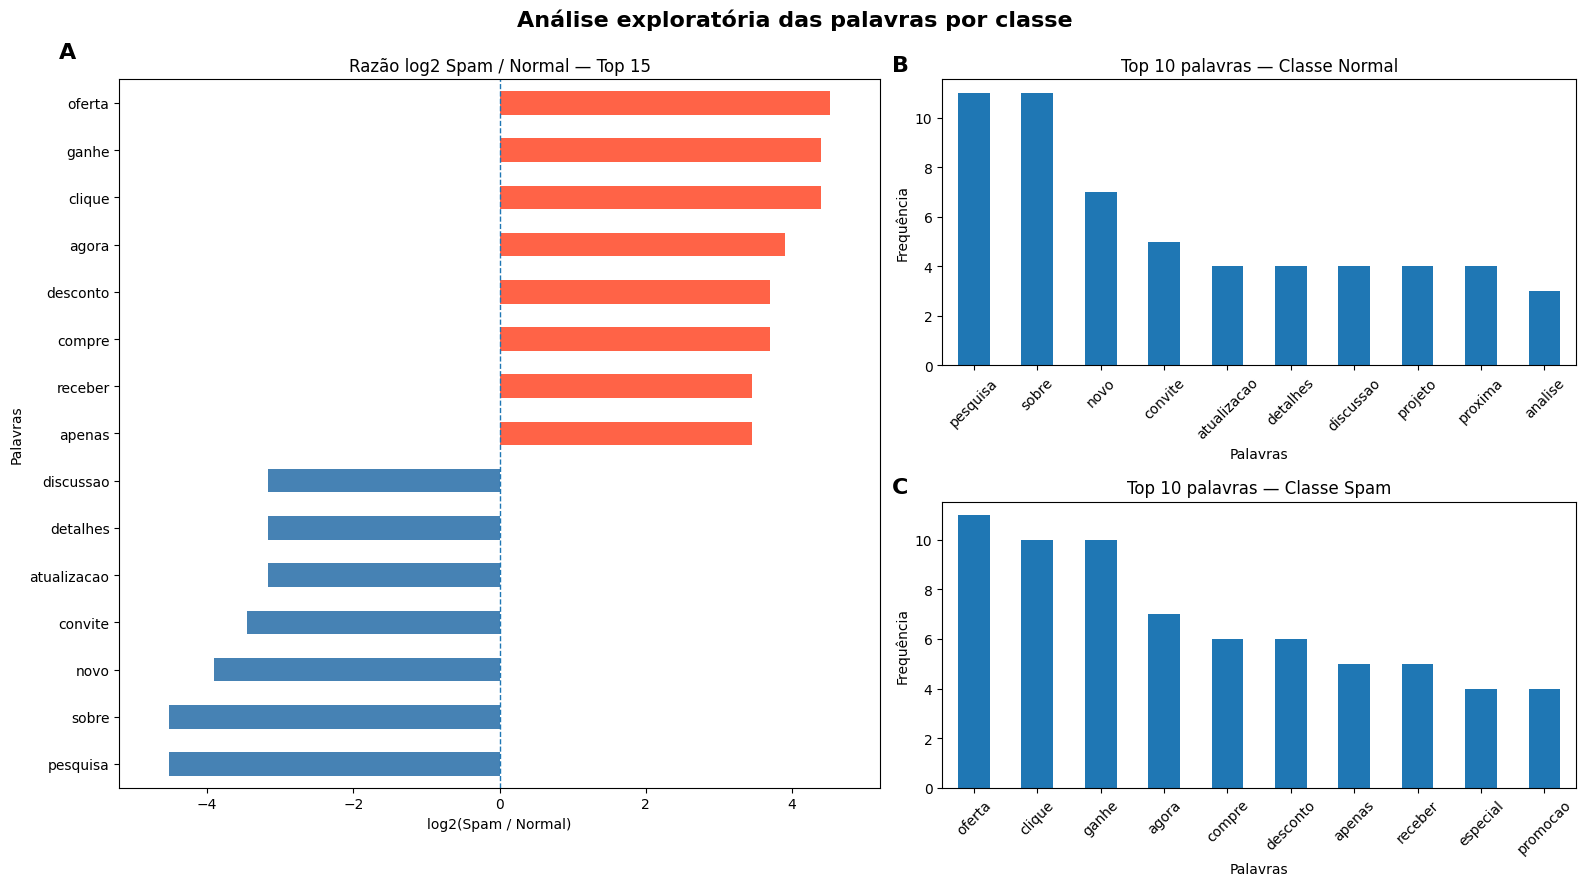

In [172]:
fig = plt.figure(figsize=(16, 9))
grid = fig.add_gridspec(nrows=2, ncols=2, width_ratios=[1.2, 1])

ax_a = fig.add_subplot(grid[:, 0])
ax_b = fig.add_subplot(grid[0, 1])
ax_c = fig.add_subplot(grid[1, 1])

# A: razão log2, centralizada em zero
top_ratio.plot.barh(ax=ax_a, color=np.where(top_ratio > 0, "tomato", "steelblue"))
ax_a.axvline(x=0, linestyle="--", linewidth=1)
ax_a.set_xlim(-top_ratio.abs().max() * 1.15, top_ratio.abs().max() * 1.15)
ax_a.set(title="Razão log2 Spam / Normal — Top 15", xlabel="log2(Spam / Normal)", ylabel="Palavras")

# B e C: palavras mais frequentes de cada classe
for ax, label in [(ax_b, "Normal"), (ax_c, "Spam")]:
    freq[label].nlargest(10).plot.bar(ax=ax, rot=45)
    ax.set(title=f"Top 10 palavras — Classe {label}", xlabel="Palavras", ylabel="Frequência")

for ax, letter in [(ax_a, "A"), (ax_b, "B"), (ax_c, "C")]:
    ax.text(-0.08, 1.03, letter, transform=ax.transAxes, fontsize=16, fontweight="bold")

fig.suptitle("Análise exploratória das palavras por classe", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

Os gráficos à direita mostram quais palavras mais aparecem em cada classe. O gráfico à esquerda é o mais informativo, pois mostra a especificidade: valores positivos altos, como o de "clique", indicam palavras fortemente associadas a Spam, e valores negativos, como o de "pesquisa", indicam palavras típicas de mensagens Normais.

#### Diagrama de Venn dos tokens

Esses gráficos sugerem que as classes usam vocabulários bem diferentes. O diagrama de Venn mede essa diferença:

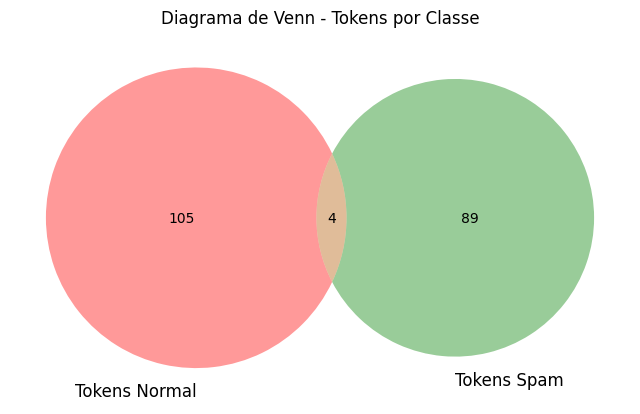

In [173]:
set_normal = set(freq.index[freq["Normal"] > 0])
set_spam = set(freq.index[freq["Spam"] > 0])

plt.figure(figsize=(8, 8))
venn2([set_normal, set_spam], set_labels=("Tokens Normal", "Tokens Spam"))
plt.title("Diagrama de Venn - Tokens por Classe")
plt.show()

In [174]:
sorted(set_normal & set_spam)

['hoje', 'programa', 'semana', 'sistema']

Somente 4 das 198 palavras aparecem nas duas classes: "hoje", "programa", "semana" e "sistema". Essa separação tão nítida facilita o trabalho do classificador, e voltaremos a ela ao interpretar os resultados.

Por enquanto, olhamos cada palavra isoladamente. Mas será que as palavras realmente aparecem de forma independente, como o Naive Bayes supõe?

#### Heatmap simplificado de coocorrência de palavras

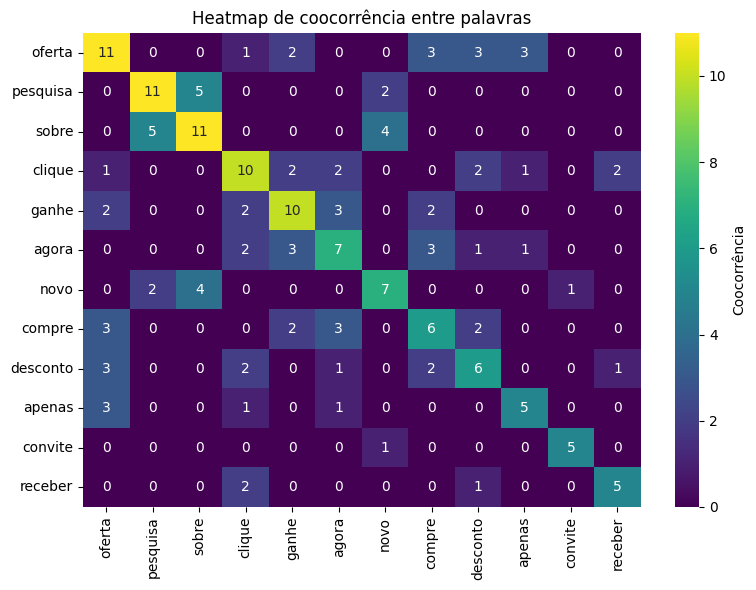

In [175]:
# Em quantas mensagens cada par das 12 palavras mais frequentes aparece junto
top_words = freq.sum(axis=1).nlargest(12).index
presence = (X_table[top_words] > 0).astype(int)
cooccurrence_matrix = presence.T @ presence

plt.figure(figsize=(8, 6))
sns.heatmap(cooccurrence_matrix, annot=True, fmt="d", cmap="viridis", cbar_kws={"label": "Coocorrência"})
plt.title("Heatmap de coocorrência entre palavras")
plt.tight_layout()
plt.show()

A diagonal mostra em quantas mensagens cada palavra aparece, e os demais valores mostram quantas vezes cada par aparece junto. "sobre" e "pesquisa" dividem 5 mensagens, e "oferta" e "desconto", 3. Aqui reside a principal limitação do Naive Bayes: o modelo ignora essas conexões. No mundo real, a suposição de independência é frequentemente violada, mas o modelo costuma funcionar bem mesmo assim, como veremos. Vamos, então, construí-lo.

### Treinando o modelo: aprender é contar

Treinar um Naive Bayes é, essencialmente, contar. Toda a experiência do agente será formada por duas tabelas de proporções, ambas calculadas a partir das contagens que já temos.

#### Cálculo das Probabilidades a Priori

A primeira é a probabilidade a priori: antes de ler a mensagem, qual é a chance de cada classe? Basta calcular a proporção de mensagens de cada classe no treino.

In [176]:
priors = df_train["class"].value_counts(normalize=True)

print(f"P(Normal) = {priors['Normal']:.4f} ({priors['Normal']*100:.2f}%)")
print(f"P(Spam)   = {priors['Spam']:.4f} ({priors['Spam']*100:.2f}%)")

P(Normal) = 0.5000 (50.00%)
P(Spam)   = 0.5000 (50.00%)


#### Construindo o vocabulário

O vocabulário, formado por todas as palavras vistas no treino, define o que o modelo é capaz de reconhecer. Ele corresponde às linhas da tabela `freq`, e cada palavra terá uma probabilidade em ambas as classes, mesmo naquela em que nunca apareceu.

In [177]:
# O vocabulário são as linhas da tabela freq produzidas pelo CountVectorizer
print(f"Tamanho do vocabulário: {len(freq)} palavras")

Tamanho do vocabulário: 198 palavras


#### Cálculo da Verossimilhança

A segunda tabela é a verossimilhança, $P(\text{palavra} | \text{classe})$. Ela é o modelo de sensor do agente: indica o quão provável é que uma mensagem de Spam contenha, por exemplo, a palavra "clique". Dividimos a contagem de cada palavra pelo total de tokens da classe. Vejamos o resultado para três palavras:

In [178]:
# P(palavra | classe) = contagem da palavra na classe / total de tokens da classe
likelihood = freq / freq.sum()
likelihood.loc[["projeto", "bonus", "clique"]]

,Normal,Spam
Word,,
projeto,0.022599,0.000000
bonus,0.000000,0.010753
clique,0.000000,0.053763


Repare nos zeros da tabela: "projeto" nunca apareceu em Spam, e "bonus" nunca apareceu em mensagens Normais. Guarde esse detalhe para o próximo passo.

<details>
  <summary>O que é verossimilhança?</summary>

A **verossimilhança** mede o quanto uma evidência é compatível com uma hipótese. Em $P(\text{palavra} | \text{classe})$, a pergunta é: se a mensagem pertence a esta classe, qual é a chance de observarmos esta palavra?

Ela não é a probabilidade da classe, pois o sentido da condição é o inverso. $P(\text{clique} | \text{Spam}) \approx 0{,}054$ indica que cerca de 5% dos tokens de Spam no treino são "clique". Já $P(\text{Spam} | \text{clique})$ é a posteriori, a resposta que buscamos, obtida ao combinar verossimilhança e priori pelo Teorema de Bayes.

Por isso, as verossimilhanças de todas as palavras do vocabulário somam 1 dentro de cada classe, mas os valores de uma mesma palavra nas duas classes não precisam somar 1.

</details>

## Exemplo prático

### Cenário 01 - Classificando uma nova mensagem

Com as duas tabelas prontas, já podemos classificar uma mensagem que acabou de chegar na conta do professor. Vamos primeiro ver quais tokens o modelo recebe:

In [179]:
# A nova mensagem de teste
NEW_EMAIL = "O projeto foi aprovado. Você receberá um bônus!"

tokens = analyzer(NEW_EMAIL)
print(f"Tokens da Nova Mensagem: {tokens}")

Tokens da Nova Mensagem: ['projeto', 'aprovado', 'recebera', 'bonus']


Aplicamos a mesma conta da teoria: buscamos o logaritmo da verossimilhança de cada token e somamos esses valores ao logaritmo da priori. Palavras fora do vocabulário não têm linha na tabela e aparecem como `NaN`.

Antes de executar as próximas células, pense: o que os zeros de "projeto" e "bonus" vão causar? O aviso *divide by zero* que aparece na execução é esperado e faz parte da resposta.

In [180]:
# Logaritmo da verossimilhança de cada token da mensagem
log_table = np.log(likelihood).reindex(tokens)
log_table

/home/oandrefonseca/.local/lib/python3.10/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


,Normal,Spam
Word,,
projeto,-3.789855,-inf
aprovado,NaN,NaN
recebera,NaN,NaN
bonus,-inf,-4.532599


In [181]:
# Score de cada classe: log-priori + soma dos log-verossimilhanças
scores = np.log(priors) + log_table.sum()
scores

class
Normal   -inf
Spam     -inf
dtype: float64

Os dois scores resultaram em infinito negativo, e o agente não tem como escolher entre eles. O motivo está na tabela: como "projeto" nunca apareceu em Spam, sua probabilidade nessa classe é zero, e o logaritmo de zero é infinito negativo. Basta um único valor desses para anular toda a soma. O mesmo ocorre com "bonus" na classe Normal.

Já "aprovado" e "recebera" não são a causa. Elas nunca apareceram no treino, ficam fora do vocabulário e são simplesmente ignoradas, sem alterar o score.

O modelo está condenando uma classe inteira porque uma palavra não apareceu em uma amostra pequena de mensagens. Ter nunca visto "projeto" em um Spam não significa que isso seja impossível. É esse raciocínio que a próxima técnica coloca em prática.

### Cenário 02 - Adicionando suavização de Laplace

A **suavização de Laplace** troca a afirmação "nunca vi esta palavra nesta classe, então é impossível" por "nunca vi, mas é possível que apareça". Para isso, soma um pequeno valor $\alpha$, geralmente 1, à contagem de cada palavra. Como isso acrescenta $\alpha$ para cada palavra do vocabulário, o denominador também precisa crescer, para que as probabilidades continuem somando 1:

$$P(\text{palavra} | \text{classe}) = \frac{\text{contagem} + \alpha}{\text{total de tokens da classe} + \alpha \times |\text{vocabulário}|}$$

Em código, essa fórmula cabe em uma linha:

In [182]:
# Quando alpha = 1, usamos a suavização de Laplace clássica
alpha = 1

likelihood_smoothed = (freq + alpha) / (freq + alpha).sum()
likelihood_smoothed.loc[["projeto", "bonus", "clique"]]

,Normal,Spam
Word,,
projeto,0.013333,0.002604
bonus,0.002667,0.007812
clique,0.002667,0.028646


Os zeros desapareceram, mas todas as probabilidades mudaram. Na classe Spam, "clique" passou de $10/186 \approx 0{,}0538$ para $11/384 \approx 0{,}0286$. Uma palavra vista uma única vez quase não muda: de $1/186 \approx 0{,}0054$ para $2/384 \approx 0{,}0052$. Já uma palavra ausente sai de zero para $1/384 \approx 0{,}0026$. Em outras palavras, a suavização retira um pouco da probabilidade das palavras frequentes e a redistribui. As palavras fora do vocabulário continuam sendo ignoradas, pois não entram nessa conta.

Agora repetimos exatamente o mesmo cálculo do Cenário 01, trocando apenas a tabela:

In [183]:
log_table_smoothed = np.log(likelihood_smoothed).reindex(tokens)
log_table_smoothed

,Normal,Spam
Word,,
projeto,-4.317488,-5.950643
aprovado,NaN,NaN
recebera,NaN,NaN
bonus,-5.926926,-4.852030


In [184]:
scores_smoothed = np.log(priors) + log_table_smoothed.sum()
print(scores_smoothed)

class
Normal   -10.937561
Spam     -11.495820
dtype: float64


In [185]:
# Classe prevista com suavização de Laplace
# idxmax() retorna o índice do maior valor da Series, que é a classe prevista
print(f"Classe Predita: {scores_smoothed.idxmax()}")

Classe Predita: Normal


Agora os dois scores são finitos, e a regra MAP consegue decidir. Até aqui, fizemos todas as contas à vista. Para aplicar o modelo em muitas mensagens, porém, seria mais prático ter tudo isso pronto.

### Cenário 03 - Executando Naive Bayes com uma biblioteca

O `MultinomialNB`, do `scikit-learn`, implementa exatamente o que acabamos de construir. Vamos treiná-lo com a mesma matriz de contagens e conferir se ele chega às mesmas probabilidades e aos mesmos scores. O parâmetro `alpha` é a mesma suavização, e o `predict_joint_log_proba` devolve os scores que calculamos à mão.

In [186]:
nb_model = MultinomialNB(alpha=alpha).fit(X, df_train["class"])
X_new = vectorizer.transform([NEW_EMAIL])

sklearn_likelihood = np.exp(nb_model.feature_log_prob_).T
sklearn_scores = nb_model.predict_joint_log_proba(X_new)[0]

print("Probabilidades iguais às da fórmula:", np.allclose(likelihood_smoothed[nb_model.classes_], sklearn_likelihood))
print("Scores iguais aos calculados à mão: ", np.allclose(scores_smoothed[nb_model.classes_], sklearn_scores))

Probabilidades iguais às da fórmula: True
Scores iguais aos calculados à mão:  True


A biblioteca também pode converter os scores em probabilidades. Isso equivale à divisão pela evidência que fizemos na demonstração teórica, agora desfazendo o logaritmo antes de normalizar:

In [187]:
# Desfaz o logaritmo e divide pela evidência, como na demonstração teórica
posterior = np.exp(scores_smoothed) / np.exp(scores_smoothed).sum()

print(posterior)
print("predict_proba:", dict(zip(nb_model.classes_, nb_model.predict_proba(X_new)[0].round(6))))

class
Normal    0.63605
Spam      0.36395
dtype: float64
predict_proba: {np.str_('Normal'): np.float64(0.63605), np.str_('Spam'): np.float64(0.36395)}


Por fim, o `make_pipeline` encadeia o pré-processamento e o modelo em um único objeto. Assim, basta entregar o texto da mensagem, e todas as etapas são aplicadas automaticamente. Este é o nosso classificador final, treinado com as mesmas mensagens.

In [188]:
spam_classifier = make_pipeline(vectorizer, MultinomialNB(alpha=alpha))
spam_classifier.fit(df_train["email"], df_train["class"])

print(f"Classe Predita: {spam_classifier.predict([NEW_EMAIL])[0]}")

Classe Predita: Normal


O classificador dá uma resposta para qualquer mensagem. Mas como saber se essa resposta costuma estar certa?

## Avaliação do classificador

Chegou a hora de abrir a prova guardada. Para perceber por que ela é necessária, medimos a **acurácia**, a proporção de acertos, tanto nas mensagens de treino quanto nas de teste. Para ter uma referência, incluímos o `DummyClassifier`, que ignora o texto e sempre responde a classe mais frequente. Um bom classificador precisa superá-lo com folga.

In [189]:
baseline = DummyClassifier(strategy="most_frequent").fit(df_train["email"], df_train["class"])

print(f"Acurácia no treino: {spam_classifier.score(df_train['email'], df_train['class']):.2%}")
print(f"Acurácia no teste:  {spam_classifier.score(df_test['email'], df_test['class']):.2%}")
print(f"Linha de base:      {baseline.score(df_test['email'], df_test['class']):.2%}")

Acurácia no treino: 100.00%
Acurácia no teste:  95.00%
Linha de base:      50.00%


A acurácia no treino é otimista, pois o modelo já conhecia aquelas mensagens. O resultado no teste é menor, porém mais honesto, e fica bem acima da linha de base. Ainda assim, a acurácia não diz que tipo de erro foi cometido. Em um filtro de spam, mandar um e-mail legítimo para o Spam é bem diferente de deixar passar uma propaganda.

<details>
  <summary>Para que serve a acurácia no treino?</summary>

A acurácia no treino não mede a qualidade do classificador, mas ajuda a diagnosticar problemas: um valor baixo sugere que o modelo não aprendeu, e uma distância grande em relação ao teste sugere sobreajuste.

</details>

### Matriz de confusão

Considerando Spam como a classe positiva, a matriz de confusão separa as previsões em quatro casos. Os **verdadeiros positivos** (VP) são os Spams identificados, e os **verdadeiros negativos** (VN), as mensagens Normais identificadas. Os **falsos positivos** (FP) são mensagens Normais enviadas para o Spam, e os **falsos negativos** (FN), Spams que chegam à caixa de entrada.

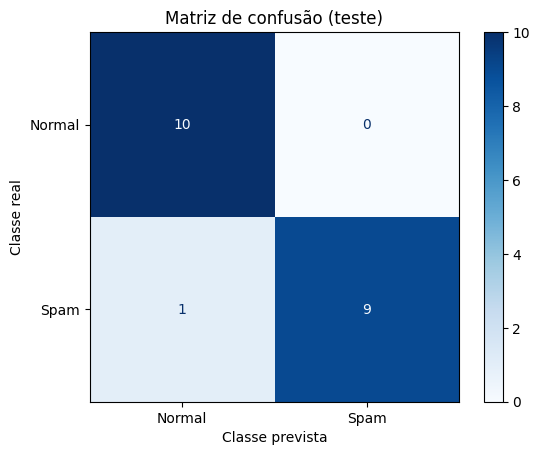

In [190]:
y_test = df_test["class"]
y_pred = spam_classifier.predict(df_test["email"])

# As linhas são a classe real, e as colunas são a classe prevista
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["Normal", "Spam"], cmap="Blues")
plt.title("Matriz de confusão (teste)")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

A partir da matriz, duas perguntas ganham resposta. A **precisão** indica, das mensagens marcadas como Spam, quantas eram mesmo Spam. A **revocação** indica, de todo o Spam existente, quanto foi encontrado. O **F1** combina as duas em um único número:

$$\text{Precisão} = \frac{VP}{VP + FP} \qquad \text{Revocação} = \frac{VP}{VP + FN} \qquad F_1 = 2 \cdot \frac{\text{Precisão} \cdot \text{Revocação}}{\text{Precisão} + \text{Revocação}}$$

Tente calcular esses valores com os números da matriz antes de executar a próxima célula.

In [191]:
# Valores lidos na matriz de confusão
vp, fp, fn = 9, 0, 1

precision = vp / (vp + fp)
recall = vp / (vp + fn)
f1 = 2 * precision * recall / (precision + recall)

print(f"Precisão: {precision:.3f} | Revocação: {recall:.3f} | F1: {f1:.3f}")

Precisão: 1.000 | Revocação: 0.900 | F1: 0.947


O `classification_report` faz esse cálculo para as duas classes de uma vez. Na linha de Spam, Precisão, Revocação e F1-escore devem coincidir com os valores acima, e **support** indica o número de mensagens de cada classe.

In [192]:
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

      Normal      0.909     1.000     0.952        10
        Spam      1.000     0.900     0.947        10

    accuracy                          0.950        20
   macro avg      0.955     0.950     0.950        20
weighted avg      0.955     0.950     0.950        20



### Análise de erros

As métricas dizem quanto o modelo errou, mas não por quê. Para investigar, olhamos diretamente a mensagem classificada de forma incorreta, usando a mesma tabela de log-verossimilhanças dos cenários. Antes de ler a explicação abaixo da tabela, tente descobrir qual palavra levou ao erro.

In [193]:
errors = (
    df_test.
    loc[y_test != y_pred, ["email", "class"]].
    assign(predita=y_pred[y_test != y_pred])
    )

display(errors)

,email,class,predita
93,Você foi escolhido para ganhar um smartphone novo,Spam,Normal


In [194]:
for message in errors["email"]:
    display(np.log(likelihood_smoothed).reindex(analyzer(message)))

,Normal,Spam
Word,,
escolhido,-5.926926,-5.257495
ganhar,NaN,NaN
smartphone,NaN,NaN
novo,-3.847484,-5.950643


O único erro é um Spam classificado como Normal. "escolhido" favorece um pouco a classe Spam, mas "novo" é bem mais provável em mensagens Normais e decide o resultado. Já "ganhar" e "smartphone" não estão no vocabulário e são ignoradas. Repare que "ganhar" lembra "ganhe", um forte indicador de Spam, mas o modelo as trata como palavras sem nenhuma relação. Técnicas como o *stemming*, que reduzem palavras a um radical comum, poderiam ajudar nesse caso.

<details>
  <summary>O que é stemming?</summary>

O **stemming** é uma técnica de pré-processamento que reduz as palavras a um radical comum, cortando sufixos e terminações. Assim, formas diferentes de uma mesma palavra passam a ser contadas como um único token. Com o `RSLPStemmer`, disponível no NLTK para o português, "ganhe", "ganhar", "ganhou" e "ganhador" se tornam "ganh".

Isso ajuda o Naive Bayes porque cada forma de uma palavra deixa de ser uma evidência separada. No nosso erro, "ganhar" estava fora do vocabulário e era ignorada, embora "ganhe" seja um forte indicador de Spam. Ao aplicar o stemming nesta mesma separação, as duas viram "ganh", o vocabulário cai de 198 para 175 tokens e a mensagem passa a ser classificada corretamente como Spam. Com isso, o modelo acerta as 20 mensagens de teste. Como cada mensagem vale 5 pontos percentuais, esse resultado é apenas um indício, não uma prova de melhora.

A técnica também tem limites, pois apenas corta o texto, sem entender o significado. Ela pode juntar palavras de sentidos diferentes, como "universidade" e "universal", que viram "univers". Também pode separar palavras relacionadas, como "clique" e "clicando", que viram "cliqu" e "clic". Além disso, o radical nem sempre é uma palavra real, o que torna as tabelas mais difíceis de ler.

</details>

## Key Takeaways

O Naive Bayes é eficiente por ser "ingênuo": ao supor que as palavras são condicionalmente independentes, dada a classe, ele troca uma probabilidade conjunta inviável por um produto simples. Treiná-lo é contar frequências, e classificar é escolher a classe de maior score, pela regra MAP, somando logaritmos para evitar problemas numéricos.

Essa simplicidade tem um ponto frágil: uma palavra do vocabulário ausente em uma classe anula todo o cálculo. A suavização de Laplace resolve esse problema, enquanto as palavras fora do vocabulário são simplesmente ignoradas. Bibliotecas como o `scikit-learn` fazem exatamente essas contas em poucas linhas, e entender a matemática é o que nos permite interpretar seus resultados.

Por fim, a qualidade de um classificador deve ser medida em dados que ele não viu. A matriz de confusão, a precisão, a revocação e o F1 revelam tipos de erro que a acurácia esconde, e a análise de erros mostra o que ainda pode ser melhorado.

## Referências

1. Russell, S. & Norvig, P. (2010). Artificial Intelligence: A Modern Approach. Prentice Hall.
2. GeeksforGeeks. Naive Bayes Classifiers. Disponível em: https://www.geeksforgeeks.org/machine-learning/naive-bayes-classifiers/.
3. scikit-learn. Naive Bayes. Disponível em: https://scikit-learn.org/stable/modules/naive_bayes.html.
4. scikit-learn. Metrics and scoring: quantifying the quality of predictions. Disponível em: https://scikit-learn.org/stable/modules/model_evaluation.html.